# Masked autoencoding

Show an encoder four of sixteen image patches and ask a lightweight decoder to recover the twelve missing patches. Here the target is the original pixel intensity.

The encoder receives only visible tokens. The decoder restores the sequence to spatial order with position-coded mask tokens. Mean squared error is measured on hidden patches. Digit labels are reserved for a frozen-feature probe.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)


import copy
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import balanced_accuracy_score, f1_score


def digit_data():
    digits = load_digits()
    train, test = train_test_split(
        np.arange(len(digits.target)), test_size=0.25, stratify=digits.target, random_state=17
    )
    x = torch.tensor(digits.images[:, None], dtype=torch.float32) / 16
    return x[train], x[test], digits.target[train], digits.target[test]


def view(x):
    n = len(x)
    padded = F.pad(x, (1, 1, 1, 1))
    offset = torch.randint(3, (n, 2))
    row = offset[:, 0, None, None] + torch.arange(8)[None, :, None]
    col = offset[:, 1, None, None] + torch.arange(8)[None, None, :]
    moved = padded[torch.arange(n)[:, None, None], 0, row, col][:, None]
    return (moved + 0.06 * torch.randn_like(moved)).clamp(0, 1)


@torch.no_grad()
def embed(model, x):
    model.eval()
    return torch.cat([model(batch) for batch in x.split(96)]).flatten(1).numpy()


def compare(initial, trained, x, t, y, yt):
    systems = [
        ("Raw pixels", x.flatten(1).numpy(), t.flatten(1).numpy()),
        ("Random encoder", embed(initial, x), embed(initial, t)),
        ("Trained encoder", embed(trained, x), embed(trained, t)),
    ]
    rows = []
    for name, a, b in systems:
        probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1200, C=1))
        probe.fit(a, y)
        guess = probe.predict(b)
        power = np.linalg.svd(b - b.mean(0), compute_uv=False) ** 2
        p = power[power > 0] / max(power.sum(), 1e-30)
        rank = float(np.exp(-(p * np.log(p)).sum())) if len(p) else 0.0
        rows.append(
            (
                name,
                float((guess == yt).mean()),
                balanced_accuracy_score(yt, guess),
                f1_score(yt, guess, average="macro"),
                rank,
            )
        )
    report(["Features", "Test accuracy", "Balanced accuracy", "Macro F1", "Effective rank"], rows)


def patches(x):
    return F.unfold(x, kernel_size=2, stride=2).transpose(1, 2)


def image(p):
    return F.fold(p.transpose(1, 2), output_size=(8, 8), kernel_size=2, stride=2)


def block(width):
    return nn.TransformerEncoderLayer(
        width, 4, dim_feedforward=width * 2, dropout=0.0, batch_first=True
    )


class PatchBackbone(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Linear(4, 32)
        self.pos = nn.Parameter(torch.randn(16, 32) * 0.15)
        self.layer = block(32)

    def tokens(self, p, ids):
        all_tokens = self.embed(p) + self.pos
        visible = all_tokens.gather(1, ids[:, :, None].expand(-1, -1, 32))
        return self.layer(visible)

    def forward(self, x):
        p = patches(x)
        ids = torch.arange(16).expand(len(x), -1)
        return self.tokens(p, ids).mean(1)


class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = PatchBackbone()
        self.project = nn.Linear(32, 24)
        self.mask = nn.Parameter(torch.zeros(1, 1, 24))
        self.pos = nn.Parameter(torch.randn(16, 24) * 0.15)
        self.decoder = block(24)
        self.out = nn.Linear(24, 4)

    def forward(self, p, visible):
        coded = self.project(self.encoder.tokens(p, visible))
        seq = self.mask.expand(len(p), 16, 24).scatter(
            1, visible[:, :, None].expand(-1, -1, 24), coded
        )
        return self.out(self.decoder(seq + self.pos))


def masks(n):
    order = torch.rand(n, 16).argsort(1)
    return order[:, :4], order[:, 4:]


def select(a, ids):
    return a.gather(1, ids[:, :, None].expand(-1, -1, a.shape[-1]))

## Train on hidden pixels

Every training image receives a new mask on each presentation. The decoder knows positions but receives pixel embeddings only at the four visible sites.

In [2]:
seed()
x, t, y, yt = digit_data()
model = Autoencoder()
initial = copy.deepcopy(model.encoder)
opt = torch.optim.AdamW(model.parameters(), lr=0.0025)
curve = []
for epoch in range(24):
    losses = []
    for ids in torch.randperm(len(x)).split(64):
        p = patches(x[ids])
        keep, hide = masks(len(p))
        pred = model(p, keep)
        loss = F.mse_loss(select(pred, hide), select(p, hide))
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append((loss.item(), len(p)))
    curve.append(sum(v * n for v, n in losses) / len(x))

## Compare against the training-set mean patch

At evaluation each example has one fixed random mask. A position-specific average from the training images gives a reconstruction baseline.

,Features,Test accuracy,Balanced accuracy,Macro F1,Effective rank
0,Raw pixels,0.97111,0.97084,0.97099,20.17443
1,Random encoder,0.91111,0.91067,0.91038,5.02471
2,Trained encoder,0.92222,0.92169,0.92187,5.53740


,Reconstruction,Hidden-pixel MSE,Hidden-pixel MAE
0,Training mean,0.07492,0.19651
1,Decoder,0.07451,0.19993


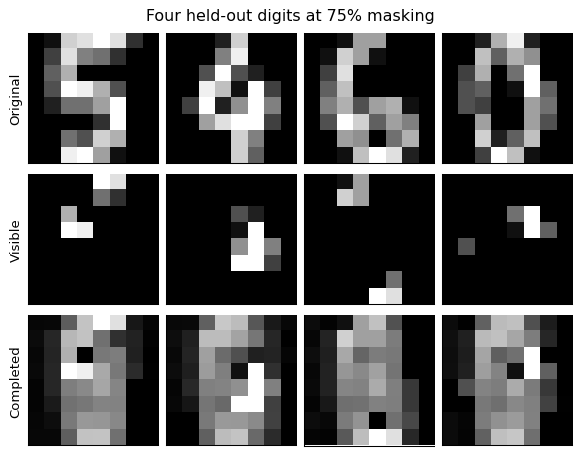

In [3]:
compare(initial, model.encoder, x, t, y, yt)
model.eval()
torch.manual_seed(101)
p = patches(t)
keep, hide = masks(len(t))
with torch.no_grad():
    pred = model(p, keep)
    changed = p.clone().scatter(
        1, hide[:, :, None].expand(-1, -1, 4), torch.full((len(t), 12, 4), 8.0)
    )
    assert torch.equal(model(changed[:8], keep[:8]), model(p[:8], keep[:8]))
    mean = patches(x).mean(0, keepdim=True).expand_as(p)
    rows = []
    for label, estimate in [("Training mean", mean), ("Decoder", pred)]:
        residual = select(estimate - p, hide)
        rows.append((label, residual.square().mean().item(), residual.abs().mean().item()))
report(["Reconstruction", "Hidden-pixel MSE", "Hidden-pixel MAE"], rows)
visible = torch.zeros_like(p).scatter(1, keep[:, :, None].expand(-1, -1, 4), select(p, keep))
completed = pred.scatter(1, keep[:, :, None].expand(-1, -1, 4), select(p, keep))
fig, axes = plt.subplots(3, 4, figsize=(6, 4.7), layout="constrained")
for line, images, label in zip(
    axes, [t, image(visible), image(completed)], ["Original", "Visible", "Completed"]
):
    for i, ax in enumerate(line):
        ax.imshow(images[i, 0].detach(), vmin=0, vmax=1, cmap="gray")
        ax.set(xticks=[], yticks=[])
    line[0].set_ylabel(label)
fig.suptitle("Four held-out digits at 75% masking")
plt.show()

## Interpreting the result

Hidden-pixel MSE fell from 0.07492 for the training mean to 0.07451 for the decoder, while MAE rose from 0.19651 to 0.19993. The two errors weight large deviations differently. The probe gained about one percentage point over the random encoder.

The finished images preserve the four observed patches. Hidden-pixel metrics prevent that copied information from artificially lowering the reconstruction error.

## Exercise

Train with eight visible patches and compare the reconstruction error and the frozen probe.

## References

[He et al. (2022), Masked Autoencoders Are Scalable Vision Learners](https://arxiv.org/abs/2111.06377)

[Alpaydin and Kaynak (1998), Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)